#  GSVA: the log-transformation (or not) of the input data

Discussion and insights


## The step discussed here

As told in the end of step1, in the terminal (from the home or working directory) the R script computed the pathways scores using the GSVA algorithm:

```
Rscript zonist/src/r/compute_gsva.R ~/spatial_thesis/spatial_metabolomics/data/brain-ellis brain-ellis-mx-clean-transposed.tsv gmt_mz.json
```

It accepted the input matrix `brain-ellis-mx-clean-transposed.tsv` containing the values as downloaded from Metaspace, but having the axes transposed for faster reading in Python and R.

_Note_: Despite parallelization, computing GSVA across ~200K coordinates required 13 hours.



## Log or not to log ? 

Note that the authors of GSVA recommend to use log-normalized data (https://github.com/rcastelo/GSVA/issues/178). This particular spatial metabolomics dataset underwent normalization (https://pubmed.ncbi.nlm.nih.gov/36473074/) beforehand. Thus I do not perform further normalization

But what about **log transformation**: is it pertinent?

I used the R script in two ways:

1. the matrix goes into GSVA directly without any transform, or
2. the matrix first is log transformed ($log_{10}$) and GSVA is computed on this log matrix

Here, the results obtained with 1. and 2. are compared. 

In [115]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
import scanpy as sc
import squidpy as sq

In [16]:
mydata_dir = "/home/johanna/spatial_thesis/spatial_metabolomics/data"
gsva_files = {"notLog": "brain-ellis-mx-clean-tr_gsva-NOinLOG.tsv",
               "yesLog": "brain-ellis-mx-clean-tr_gsva-YESinLOG.tsv"}

In [17]:
gsva_results = {}

In [18]:
for k in gsva_files.keys():
    tmp = pd.read_csv(
         os.path.join(mydata_dir, "brain-ellis", 
                        gsva_files[k]), sep="\t", index_col=0, header=0)
    gsva_results[k] = tmp

In [19]:
list(gsva_results.keys())

['notLog', 'yesLog']

In [20]:
gsva_results["notLog"].iloc[:3, :3]

,hsa00100,hsa00120,hsa00140
pathway_id,,,
x0_y0,-0.833333,-0.756579,-0.633117
x0_y1,-0.833333,-0.756579,-0.633117
x0_y2,-0.833333,-0.756579,-0.633117


In [21]:
gsva_results["yesLog"].iloc[:3, :3]

,hsa00100,hsa00120,hsa00140
pathway_id,,,
x0_y0,-0.744091,-0.710526,-0.659091
x0_y1,-0.744091,-0.710526,-0.659091
x0_y2,-0.744091,-0.710526,-0.659091


_question_ : How many pathways if data was NOT log-transformed?

In [27]:
len(list(gsva_results["notLog"].columns))

105

_question_ : How many pathways if data was **log-transformed**?

In [28]:
len(list(gsva_results["yesLog"].columns))

115

In [25]:
len(set(
    list(gsva_results["yesLog"].columns)
).intersection(set(
    list(gsva_results["notLog"].columns)
)))  # pathways in common

105

In [29]:
len(set(
    list(gsva_results["yesLog"].columns)
) - set(
    list(gsva_results["notLog"].columns)
))  # pathways difference

10

As observed, the result from the **log transformed** , compared to the other result, has the same 105 pathways, but also has 10 pathways more, for a total of 115.

### comparison, overview

In [162]:
sample_features = np.random.choice(np.array(gsva_results["notLog"].columns), 9, replace=False)

Text(0.5, 23.52222222222222, 'Not-Log ')

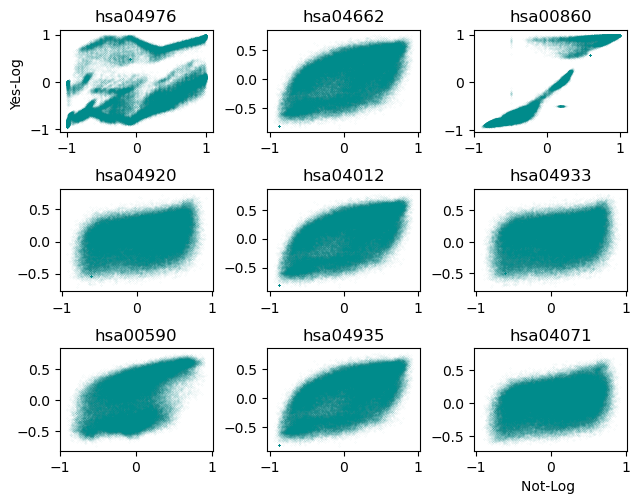

In [177]:
fig, axes = plt.subplots(3, 3, sharey=False)
fig.tight_layout(pad=1.08, h_pad=2, w_pad=0.8)
flattened_axs = axes.flatten()
fig_count = 0
for f in list(sample_features):  # ['hsa04014', 'hsa04014']: 
    v = gsva_results["notLog"][f].tolist()
    w = gsva_results["yesLog"][f].tolist()
    flattened_axs[fig_count].scatter(x=v, y=w, s=0.01, alpha=0.2, color="darkcyan")
    flattened_axs[fig_count].title.set_text(f)
    fig_count += 1 
flattened_axs[0].set_ylabel("Yes-Log ")  
flattened_axs[fig_count-1].set_xlabel("Not-Log ")


In [180]:
fig.savefig("values_gsva_inputlogvsnot.jpg")

In [182]:
plt.close()

In [205]:
def strlist_2D_to_coords_arr(strlist):
    x = []
    y = []
    for s in strlist:
        elems = s.split("_")
        x.append(int(elems[0].replace("x","")))
        y.append(int(elems[1].replace("y","")))

    return np.array([x,y]).T


In [206]:
def compose_adata(df, coordinates_arr, features):
    adata = ad.AnnData(df,
                   obsm={"spatial": np.array(coordinates_arr)},
                   varm={"transcripts" : np.array(features)})
    adata.uns['spatial'] = { 'MY_SLICE7_NAME' : {
        'scalefactors': {'fiducial_diameter_fullres': 100,
        'spot_diameter_fullres': 1, 
        'tissue_hires_scalef': 0.5, 
        'tissue_lowres_scalef': 0.5 }} }
    return adata

### clustering: the gsva result obtained from data that was 'log'

In [207]:
adata = compose_adata(
    gsva_results["yesLog"],
    strlist_2D_to_coords_arr(
         gsva_results["yesLog"].index.tolist()                         
                      ),
    list(gsva_results["yesLog"].columns)
                     )

In [208]:
adata

AnnData object with n_obs × n_vars = 171150 × 115
    uns: 'spatial'
    obsm: 'spatial'
    varm: 'transcripts'

In [209]:
adata.var

""
hsa00100
hsa00120
hsa00140
hsa00561
hsa00564
...
hsa05022
hsa05417
hsa05415
hsa04931


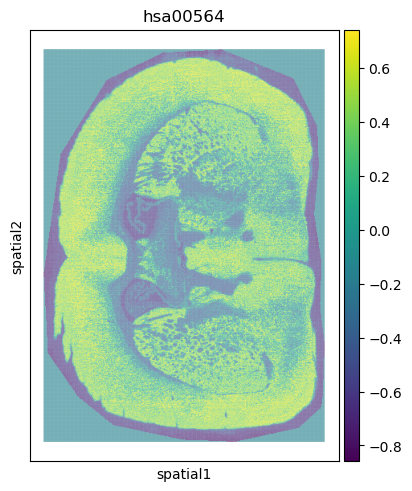

In [210]:
sq.pl.spatial_scatter(adata, color=["hsa00564"], img=False)

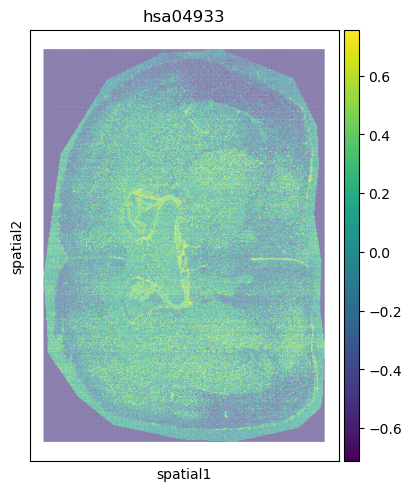

In [211]:
sq.pl.spatial_scatter(adata, color=["hsa04933"], img=False)

In [212]:
sc.pp.pca(adata, n_comps=min(10, len(gsva_results["yesLog"].columns) - 1))

In [213]:
adata

AnnData object with n_obs × n_vars = 171150 × 115
    uns: 'spatial', 'pca'
    obsm: 'spatial', 'X_pca'
    varm: 'transcripts', 'PCs'

In [214]:
sc.pp.neighbors(adata)  # nearest neighbor graph
sc.tl.umap(adata)

In [215]:
sc.tl.leiden(adata, resolution=0.5, key_added="leiden0.5")   

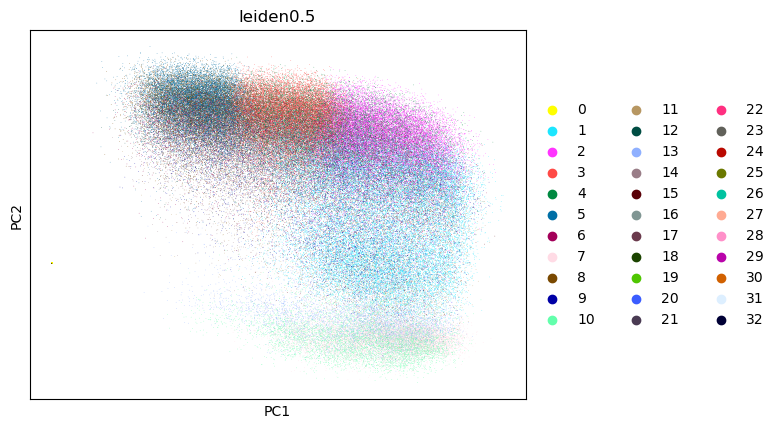

In [216]:
sc.pl.pca(adata, color=["leiden0.5"])

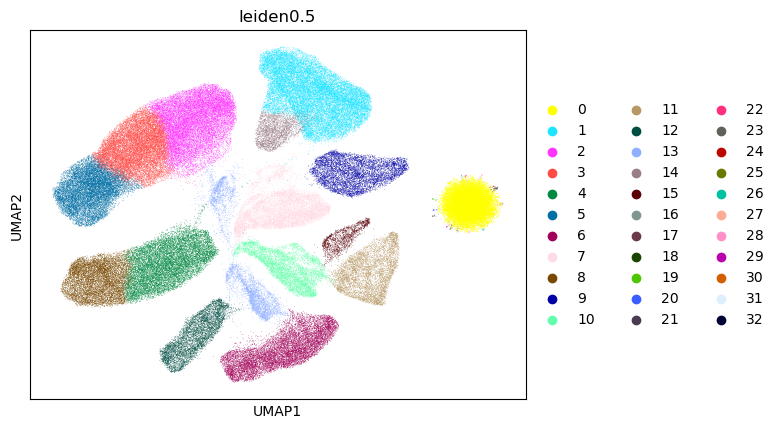

In [217]:
sc.pl.umap(adata, color=["leiden0.5"])

In [218]:
adata

AnnData object with n_obs × n_vars = 171150 × 115
    obs: 'leiden0.5'
    uns: 'spatial', 'pca', 'neighbors', 'umap', 'leiden0.5', 'leiden0.5_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'transcripts', 'PCs'
    obsp: 'distances', 'connectivities'

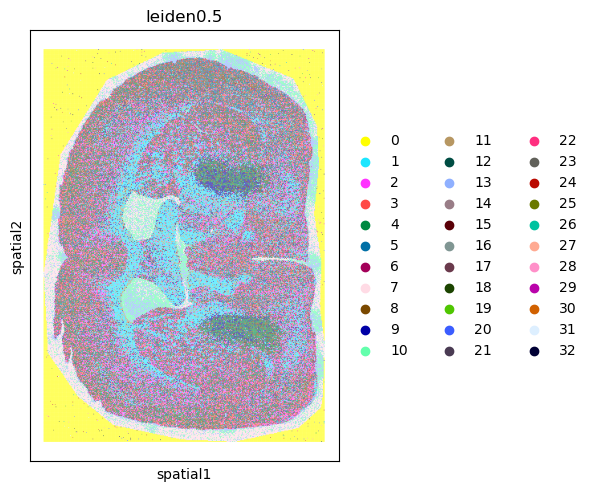

In [219]:
sq.pl.spatial_scatter(adata, color=["leiden0.5"], img=False)

In [220]:
sc.tl.leiden(adata, resolution=0.2, key_added="leiden0.2")

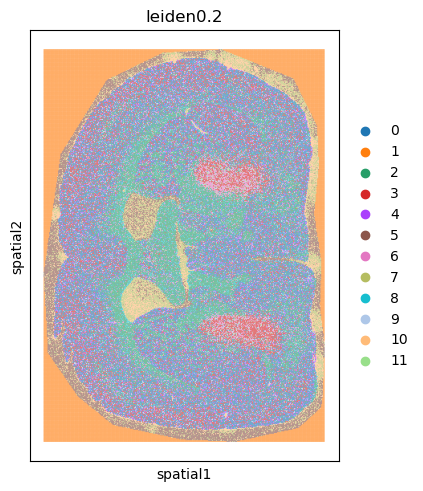

In [221]:
sq.pl.spatial_scatter(adata, color=["leiden0.2"], img=False)

### clustering: the gsva result obtained from data that was 'NOT log'

In [222]:
adata_no = compose_adata(
    gsva_results["notLog"],
    strlist_2D_to_coords_arr(
         gsva_results["notLog"].index.tolist()                         
                      ),
    list(gsva_results["notLog"].columns)
                     )

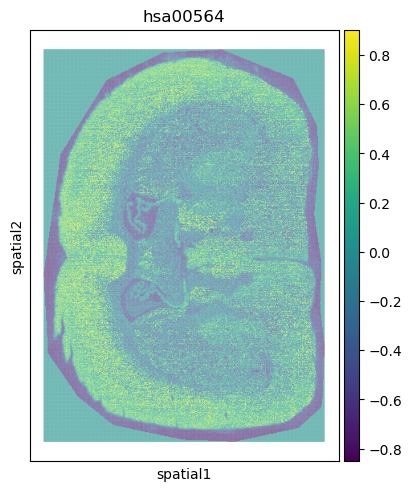

In [223]:
sq.pl.spatial_scatter(adata_no, color=["hsa00564"], img=False)

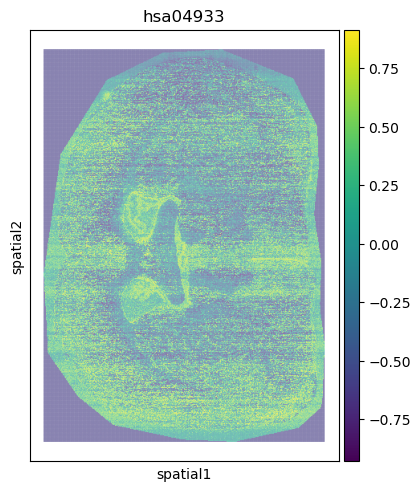

In [224]:
sq.pl.spatial_scatter(adata_no, color=["hsa04933"], img=False)

In [225]:
sc.pp.pca(adata_no, n_comps=min(10, len(gsva_results["notLog"].columns) - 1))

In [226]:
adata_no

AnnData object with n_obs × n_vars = 171150 × 105
    uns: 'spatial', 'pca'
    obsm: 'spatial', 'X_pca'
    varm: 'transcripts', 'PCs'

In [227]:
sc.pp.neighbors(adata_no)  # nearest neighbor graph
sc.tl.umap(adata_no)

In [230]:
sc.tl.leiden(adata_no, resolution=0.5, key_added="leiden0.5")   

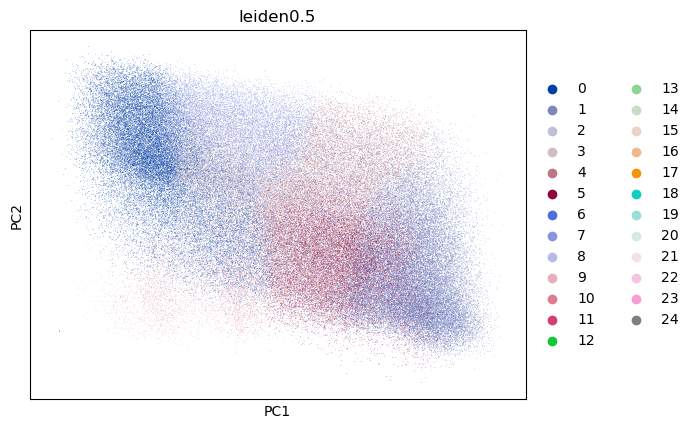

In [231]:
sc.pl.pca(adata_no, color=["leiden0.5"])

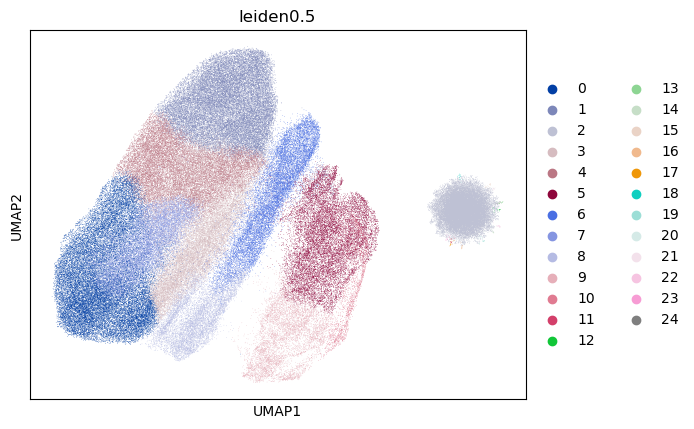

In [232]:
sc.pl.umap(adata_no, color=["leiden0.5"])

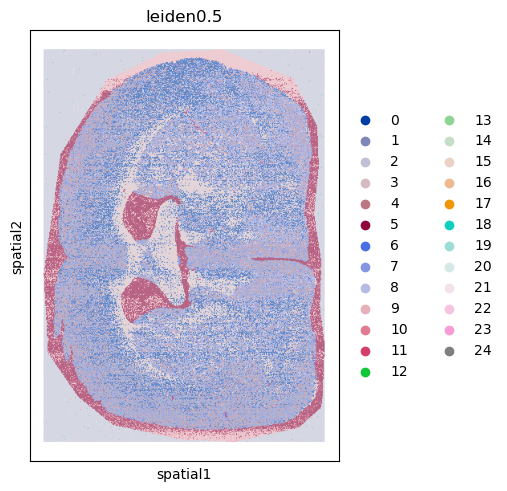

In [233]:
sq.pl.spatial_scatter(adata_no, color=["leiden0.5"], img=False)

In [234]:
sc.tl.leiden(adata_no, resolution=0.2, key_added="leiden0.2")

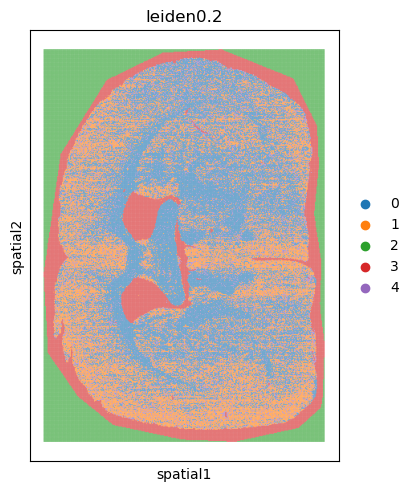

In [235]:
sq.pl.spatial_scatter(adata_no, color=["leiden0.2"], img=False)

In [ ]:
#  try to increment a bit the clusters for a final check

In [236]:
sc.tl.leiden(adata_no, resolution=0.6, key_added="leiden0.6")

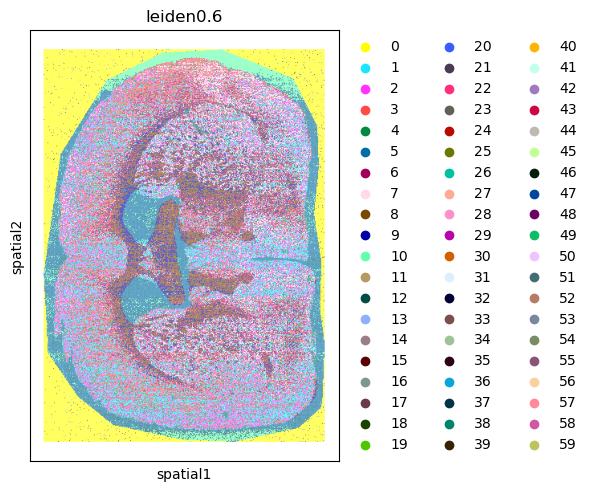

In [237]:
sq.pl.spatial_scatter(adata_no, color=["leiden0.6"], img=False)

## DECISION

<div class="alert alert-block alert-info">
<b>From now, always log-transform data before GSVA:</b> When doing log-transformation the computed pathways are more numerous, and the cluster of the pathways scores yields groups that keep more coherence with anatomical regions
</div>

In [ ]:
del adata_no

-------------------------------------

# Spatial domanis only for the retained result

Spatial domains as in https://www.sc-best-practices.org/spatial/domains.html

In [238]:
nn_graph_genes = adata.obsp["connectivities"]
# spatial proximity graph
sq.gr.spatial_neighbors(adata)
nn_graph_space = adata.obsp["spatial_connectivities"]

In [241]:
alpha = 0.4  # weight for the spatial (coords) nngraph

joint_graph = (1 - alpha) * nn_graph_genes + alpha * nn_graph_space
sc.tl.leiden(adata, 
             resolution=1.4,
             adjacency=joint_graph, key_added="squidpy_domains(leiden1.4)")

See the squidpy domains with leiden resolution as specified

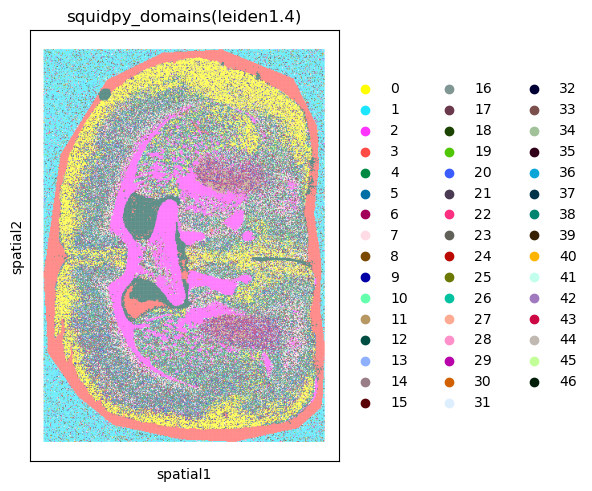

In [243]:
sq.pl.spatial_scatter(adata, color=["squidpy_domains(leiden1.4)"], img=False) 
# with leiden 0.5